In [19]:
import matplotlib.pyplot as plt
import numpy as np

from pyrokinetics import template_dir
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.pyroscan import PyroScan
from pathlib import Path

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)

In [20]:
json_path = template_dir / "outputs" / "CGYRO_linear_scan"
pyro_scan = PyroScan(pyroscan_json=json_path / "pyroscan.json", load_base_pyro=True)

pyro_scan.load_gk_output()

Extent(pyro_scan.gk_output)

/home/Felix/Documents/Physics_Work/Project_Codes/Papers/pyrokinetics/src/pyrokinetics/gk_code/gk_output.py:694: UserWarning: Mode frequency may not be accurate due to low temporal resolution
  warnings.warn(
/home/Felix/Documents/Physics_Work/Project_Codes/Papers/pyrokinetics/src/pyrokinetics/gk_code/gk_output.py:694: UserWarning: Mode frequency may not be accurate due to low temporal resolution
  warnings.warn(


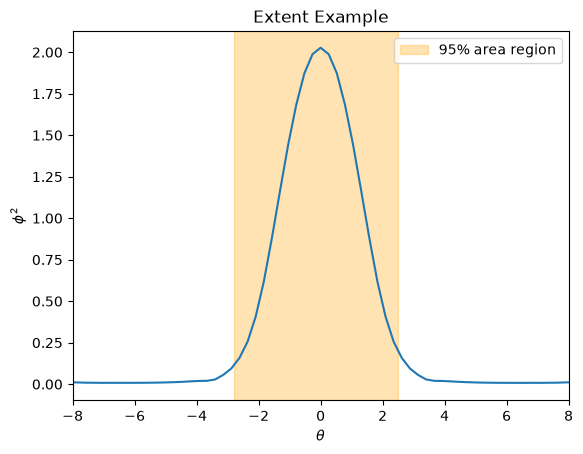

In [31]:
plt.figure()

np.real(pyro_scan.gk_output["phi_squared"].isel(ky=2)).plot()

region = plt.axvspan(
    pyro_scan.gk_output["bounds"].sel(bound="lo").isel(ky=2).item(),
    pyro_scan.gk_output["bounds"].sel(bound="hi").isel(ky=2).item(),
    color="orange",
    alpha=0.3,
    label="95% area region",
)

plt.title("Extent Example")
plt.xlabel(r"$\theta$")
plt.ylabel(r"$\phi^2$")
plt.xlim(-8, 8)
plt.legend(handles=[region], loc="upper right")

plt.savefig(plots_dir / "Extent Example.png", dpi=300, bbox_inches="tight")
plt.show()